## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

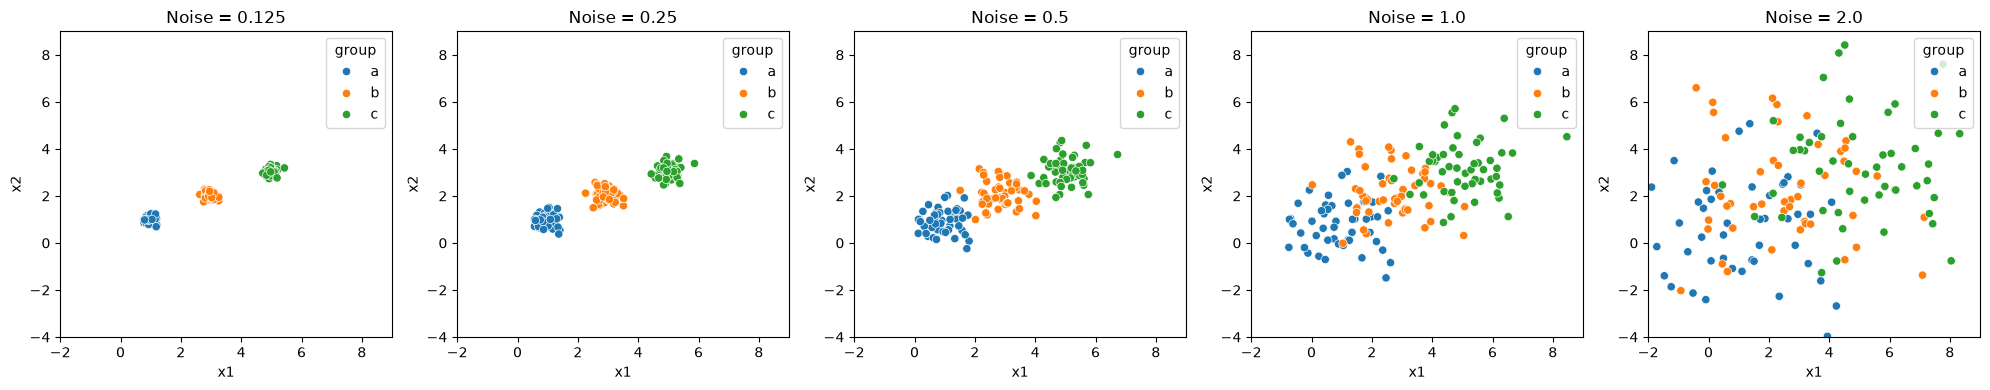

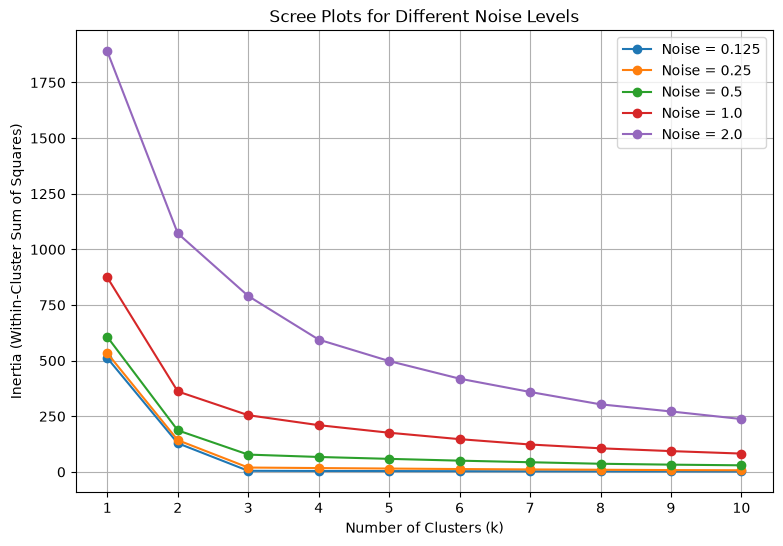

In [2]:
# Your Phase 1 solution to the problem goes here.
#Q1
# QUESTION 1: 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])

    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})

    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]



# QUESTION 2: 


fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    sns.scatterplot(data=datasets[i], x='x1', y='x2',
                    hue='group', ax=axes[i])
    axes[i].set_title('Noise = ' + str(noise_levels[i]))
    axes[i].set_xlim(-2, 9)
    axes[i].set_ylim(-4, 9)

plt.tight_layout()
plt.show()

# Explanation:

#The clusters become more spread out when the noise increases and they start to overlap.
#When the noice level are lower the three groups are much easier to tell apart.
#At higher noise levels, like 2.0, it is very difuclt to see where one group ends and 
#another begins.



# QUESTION 3: 

plt.figure(figsize=(9, 6))

for i in range(5):
    X = datasets[i][['x1', 'x2']]
    inertia_values = []

    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=100, n_init=10)
        model.fit(X)
        inertia_values.append(model.inertia_)

    plt.plot(range(1, 11), inertia_values, marker='o',
             label='Noise = ' + str(noise_levels[i]))

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Scree Plots for Different Noise Levels')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.show()

# Explanation:

#A clear elbow at k = 3 is present at lower noise levels.
#When the noise level incrases it result in the elborw beocming less clear,
#this makes it harder to choose the optimal k value.
#Higher noise also has the impact of increasing inertia becuase points are more spread out
#At noise = 2.0, there is no obvious elbow at k =3.




# QUESTION 4: 

# The elbow is where adding more clusters stops making
# a big difference in reducing inertia. 
# With three oringal groups In this example going from 1 to 3 
# clusters has a large impact on reduces inertia when noise is low
#Becuase the main groups are already seperated after k = 3 adding more clusters 
#makes minimal improvments. This is why k = 3 is the right choice when the noise is low


Number of countries: 148
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.877177            20.553464   
50%             959.535443            81.506703   
75%            5289.998320           326.267753   
max          778397.200000          2520.398541   

       Percent of Government Spending  Percent of GDP  
count                      148.000000      148.000000  
mean                         0.061510        0.019619  
std                          0.046207        0.015033  
min                          0.004896        0.000054  
25%                          0.031352        0.010413

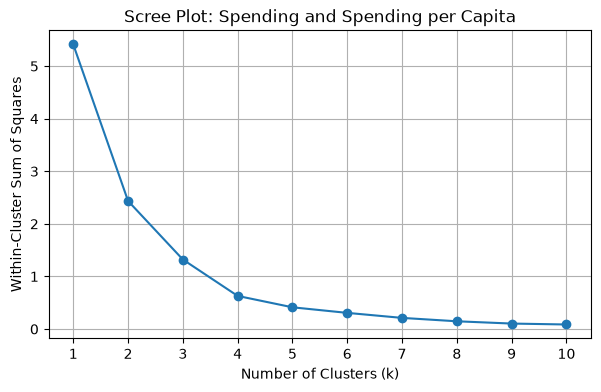

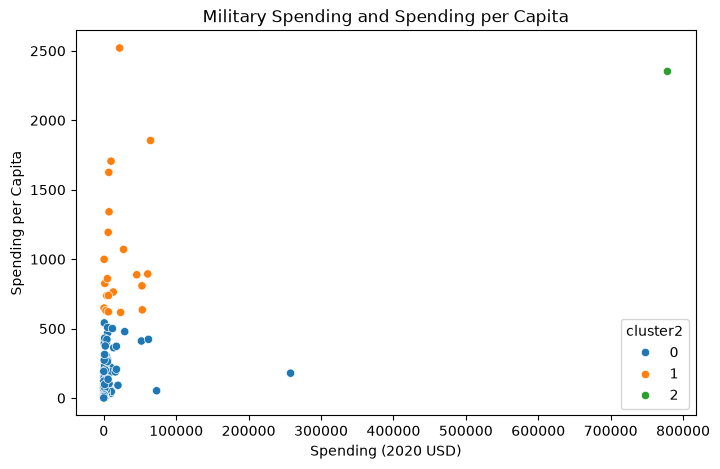

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                      126.0    5943.346303  24858.961064       8.622460   
1                       21.0   19975.991473  21749.736747     405.790494   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0            162.761743     580.758315    3225.333414  257973.429834   
1           4980.428135    7269.880030   27300.894701   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mea

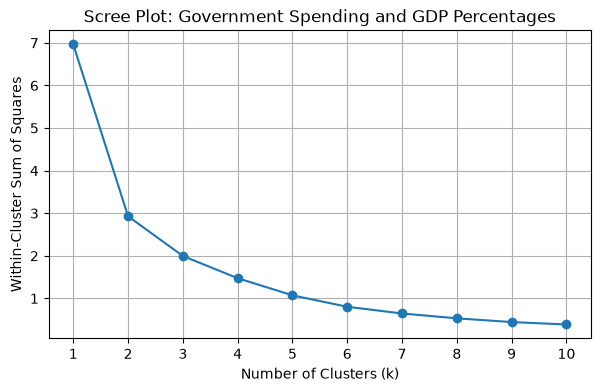

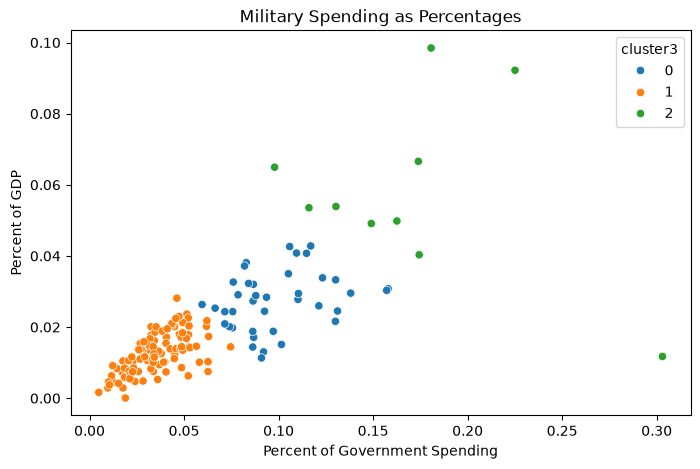

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       mi

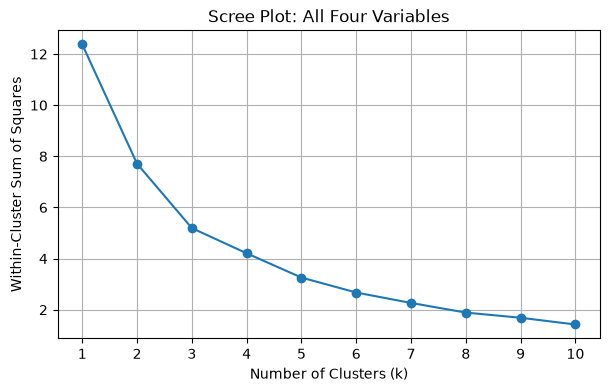

         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                      111.0    7086.472777   26479.379918     8.622460   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                       31.0    8786.086602   17901.909108   162.373364   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          130.010211    567.650747   3910.107493  257973.429834   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          467.787851   1404.787234   7739.166193   72937.064048   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...             

In [3]:
#Q2
# QUESTION 1:

df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')

df = df[df['Year'] == 2020].copy()
df = df.dropna()

columns = ['Spending (2020 USD)', 'Spending per Capita',
           'Percent of Government Spending', 'Percent of GDP']

print("Number of countries:", len(df))
print(df[columns].dtypes)
print(df[columns].describe())

# Explanation:
#filtering tro 2020 and removing all the msising values leaves me with 148 countires, 
#with all four vaiables being numeric so I do not need to change that. 



# QUESTION 2: 

cols2 = ['Spending (2020 USD)', 'Spending per Capita']

# Min-max normalization
X2 = df[cols2].copy()

for col in cols2:
    X2[col] = (X2[col] - X2[col].min()) / (X2[col].max() - X2[col].min())

# Scree plot
wcss2 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X2)
    wcss2.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss2, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Scree Plot: Spending and Spending per Capita')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# K-means clustering
model2 = KMeans(n_clusters=3, random_state=100, n_init=10)
df['cluster2'] = model2.fit_predict(X2)

# Scatterplot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=cols2[0], y=cols2[1],
                hue='cluster2', palette='tab10')
plt.title('Military Spending and Spending per Capita')
plt.show()

# Describe table
print(df.groupby('cluster2')[cols2].describe())

# United States and countries by cluster
print(df[df['Country'] == 'United States of America']
      [['Country', 'cluster2'] + cols2])

print(df.groupby('cluster2')['Country'].apply(list))

# Explanation:
#The elbow of the scree plot is around k = 3 which results in me chooosing 3 clsuters. 
#In cluser 0 is where most countries are which has a lower spending per capita, cluster 2 contains the
#coutnries with higher spending per capita, United states is the only country in here due to its high miltary spending. 



# QUESTION 3: 

cols3 = ['Percent of Government Spending', 'Percent of GDP']

# Min-max normalization
X3 = df[cols3].copy()

for col in cols3:
    X3[col] = (X3[col] - X3[col].min()) / (X3[col].max() - X3[col].min())

# Scree plot
wcss3 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X3)
    wcss3.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss3, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Scree Plot: Government Spending and GDP Percentages')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# K-means clustering
model3 = KMeans(n_clusters=3, random_state=100, n_init=10)
df['cluster3'] = model3.fit_predict(X3)

# Scatterplot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=cols3[0], y=cols3[1],
                hue='cluster3', palette='tab10')
plt.title('Military Spending as Percentages')
plt.show()

# Describe table
print(df.groupby('cluster3')[cols3].describe())

# United States and countries by cluster
print(df[df['Country'] == 'United States of America']
      [['Country', 'cluster3'] + cols3])

print(df.groupby('cluster3')['Country'].apply(list))

# Explanation:

#Again the scree plot leads me twoards 3 clusters but the elbow is less clear.
#cluster 1 has the lowest miltary spending percentages wise, 0 is in the middle, and 2
# has the higheset percentages, in this senario United States falls in 0 rather than being in alone in the previous example

#This explains that a coutnry can spend alot but becuase of other spending and gdp it might not have the highest percentage.



# QUESTION 4: 

X4 = df[columns].copy()

# Min-max normalization
for col in columns:
    X4[col] = (X4[col] - X4[col].min()) / (X4[col].max() - X4[col].min())

# Scree plot
wcss4 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X4)
    wcss4.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss4, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Scree Plot: All Four Variables')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# K-means clustering
model4 = KMeans(n_clusters=3, random_state=100, n_init=10)
df['cluster4'] = model4.fit_predict(X4)

# Describe table
print(df.groupby('cluster4')[columns].describe())

# Compare clusters
print(pd.crosstab(df['cluster2'], df['cluster4']))
print(pd.crosstab(df['cluster3'], df['cluster4']))

# United States and countries by cluster
print(df[df['Country'] == 'United States of America']
      [['Country', 'cluster2', 'cluster3', 'cluster4']])

print(df.groupby('cluster4')['Country'].apply(list))

# Explanation:
# Looking at al four varaibles, I chose k =3 to compare for all the previous queiotns, 
# which amesk cluster 0 have the most countries with lower sepnding, cluster 1 have 6 countires with 
#a high spending per capita. and cluster 2 has countries that spend a large percentage on their military. 
#
#Unlike Quesitons 2, The us is no longer on its own cluster beucaes we are looking at more than just the total spending and spending per capita.



# QUESTION 5: 

# I think K-means was uself beucase it allowed me to see how countries are differnt in military spending
# Some might spend a large number overall, while others spend a large amount percentage wise compared
# to their use of resources, adn these tell different stories. However one note is that extreme values such as
#the country we live in, the US, can have an impact on the clusters, so the reuslts do not give a complete picture of miltary spending.



## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** dcfc80bbf58ccdd07e6cb3a6951a667cc14639e1
- **AI tool and model used:** Chat GPT Instant

### *Prompts used

1. Based upon this code *paste code* attmpeting to answer this question *paste Q1* suggest edits, new functions, or removals of code that would make this code answer the question at hand better. Do not make the changes just tell me what could be changed.
2. *Same as above but for q2*

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. create separate scree plots for each noise level
2. Add teh actual k-means cluster centers to the scatterplots
3. compare the oringal groups to the K-means predctions
4. Calculate silhoute scores for different k values
5. Add a numerical clutsering accuacy
6. Add a table showing how much inertia decreases s k increases
7. Ad silhouette scores to help select the best k
8. Highlight the US on Scatterplots
9. Create a summary table comparing the clusters
10. Compare how countries change clusters between models
11. Test how remvoing the US affects clustering
12. Add a two dimensional visualization of the four varaible clustering

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept  | this will make the elbow easier to identify so seems like a strong change |
| 2 | reject | Whilie this could be useful for visualizing it does not seem like it would impact the strength of my repsonse |
| 3 | Accept | This will allow me to visually compare the original groups with the algorithm's results and see how noise affects clustering accuacy |
| 4 | Accept | This will help address the difficulty of accepting K  |
| 5 | Accept | This would give nemerical evidence of how much increasing noise affects clustering quality |
| 6 | Reject | This Seems unnesascary as the selection of K is already suppported elsewhere |
| 7 | Reject | This Seems unnesascary as the inforamtion from this table is obtained elsewhere |
| 8 | Accept | This will allow me to immediately see how the U.S. compares with other countires |
| 9 | Accept | Thsi will make it much easier to identify what makes each cluster different without looking through the full descriptive stats |
| 10 | Accept | This would help support my explanation that the reuslts change depending on which miltary spending variables are used |
| 11 | Accept | This will help provide evidence for my q5 quesiton about how extreme values affect clustering|
| 12 | Reject | This seems liek a complex and unesscary to move to answer quesitons that i have already|

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

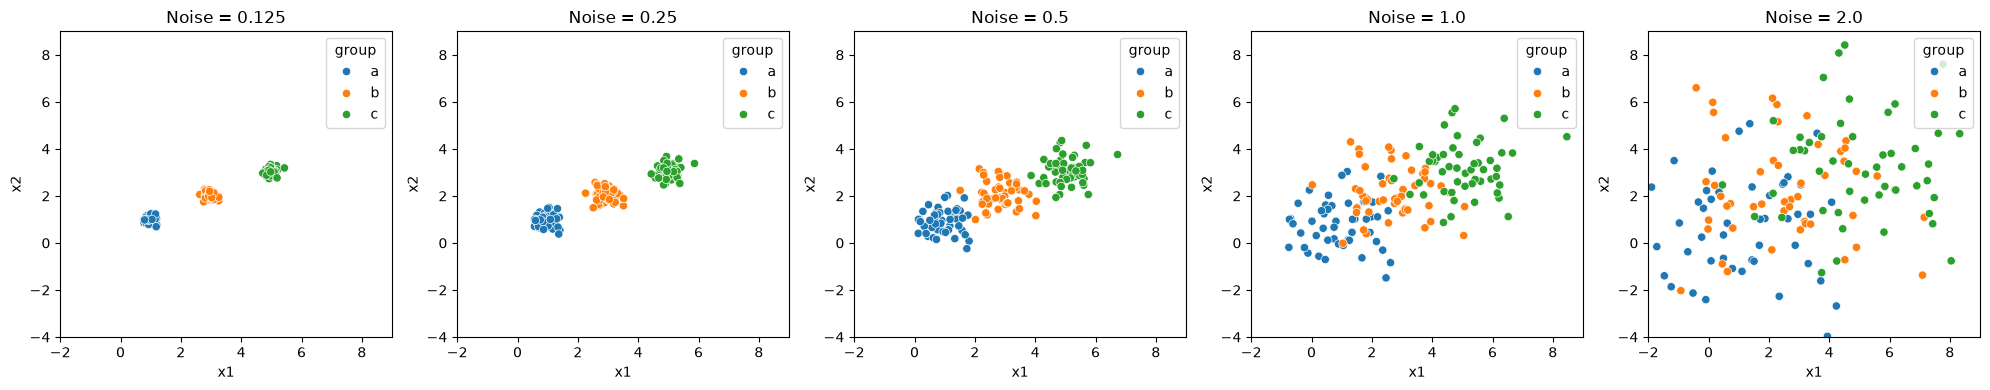

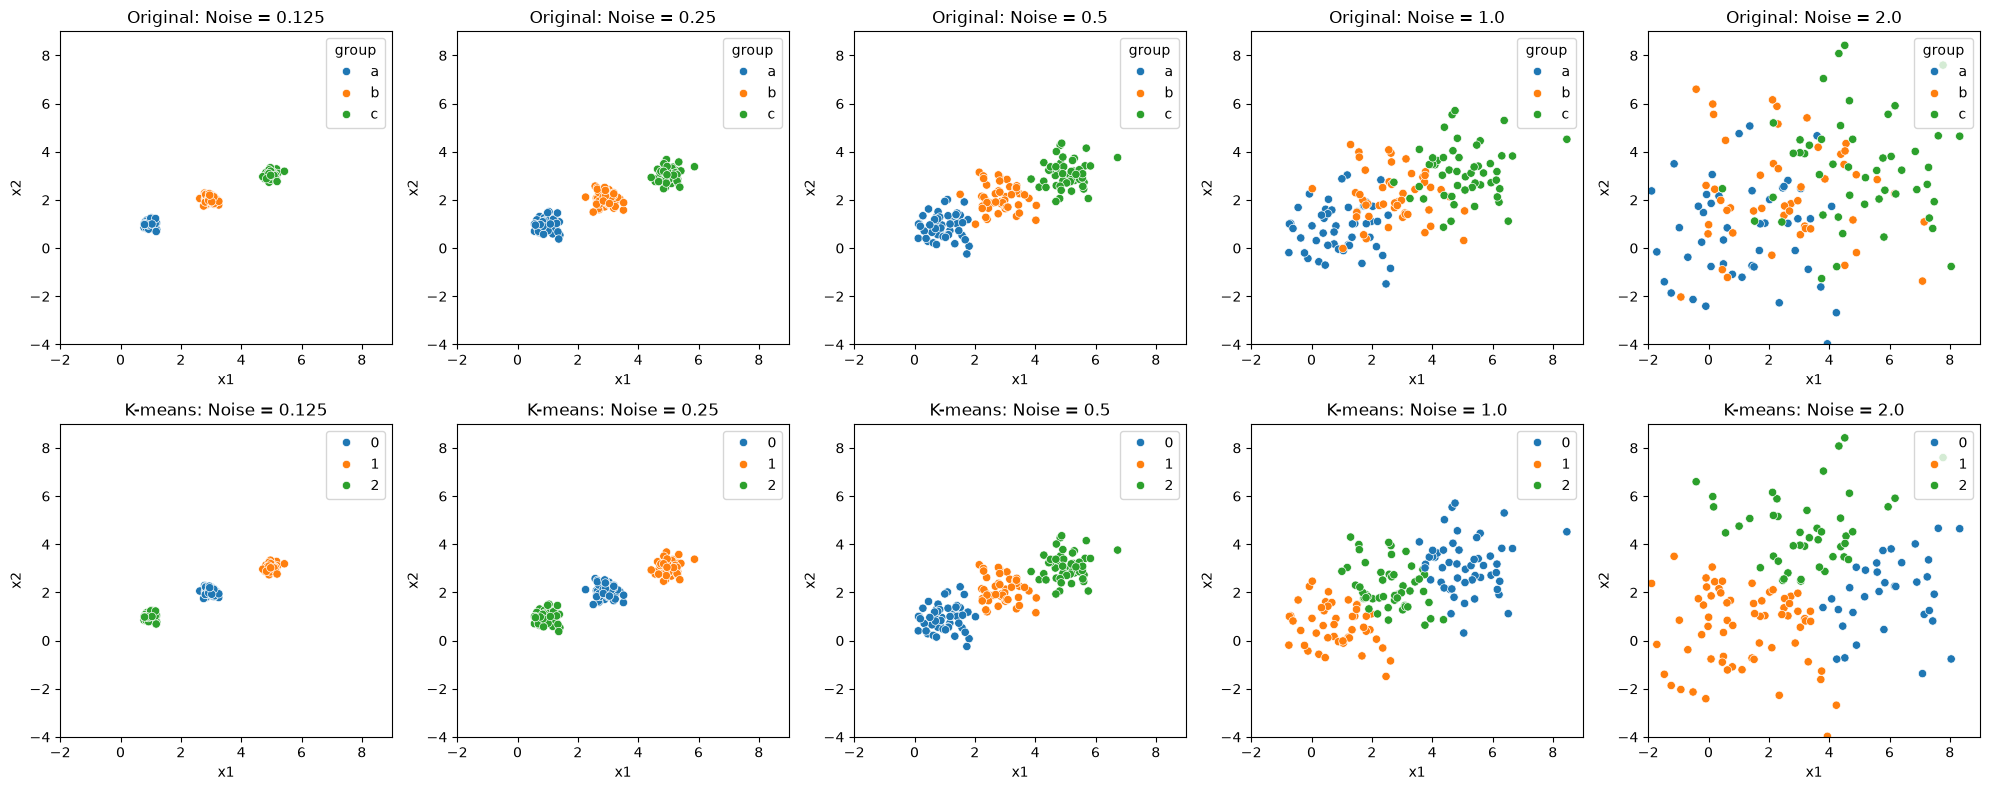

   Noise  ARI Score
0  0.125   1.000000
1  0.250   1.000000
2  0.500   0.960278
3  1.000   0.545923
4  2.000   0.206218


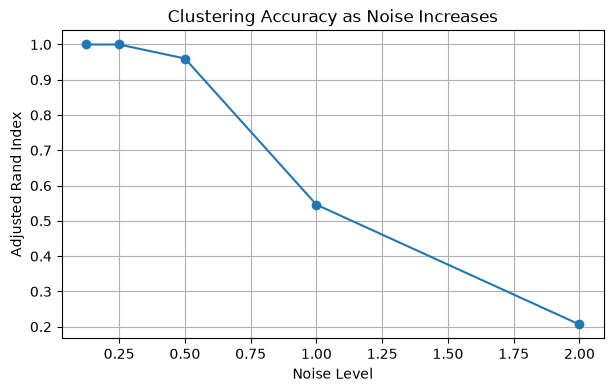

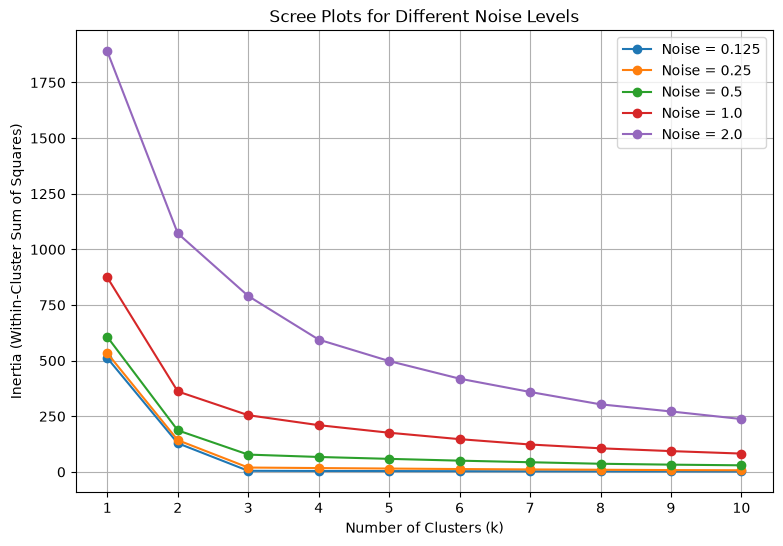

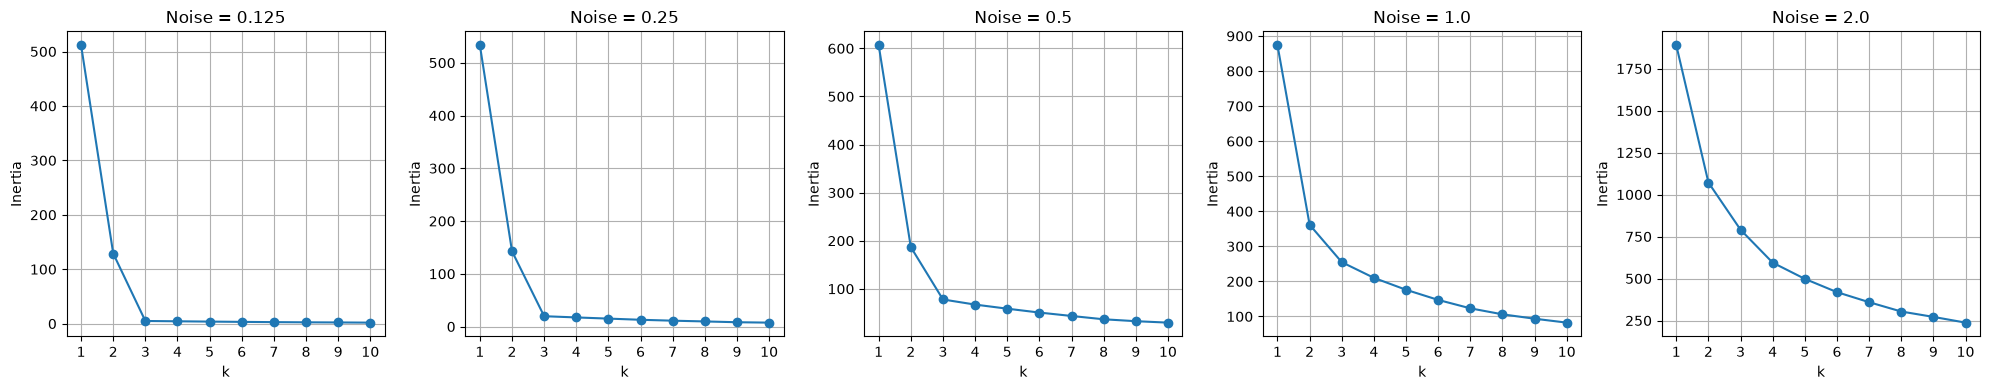

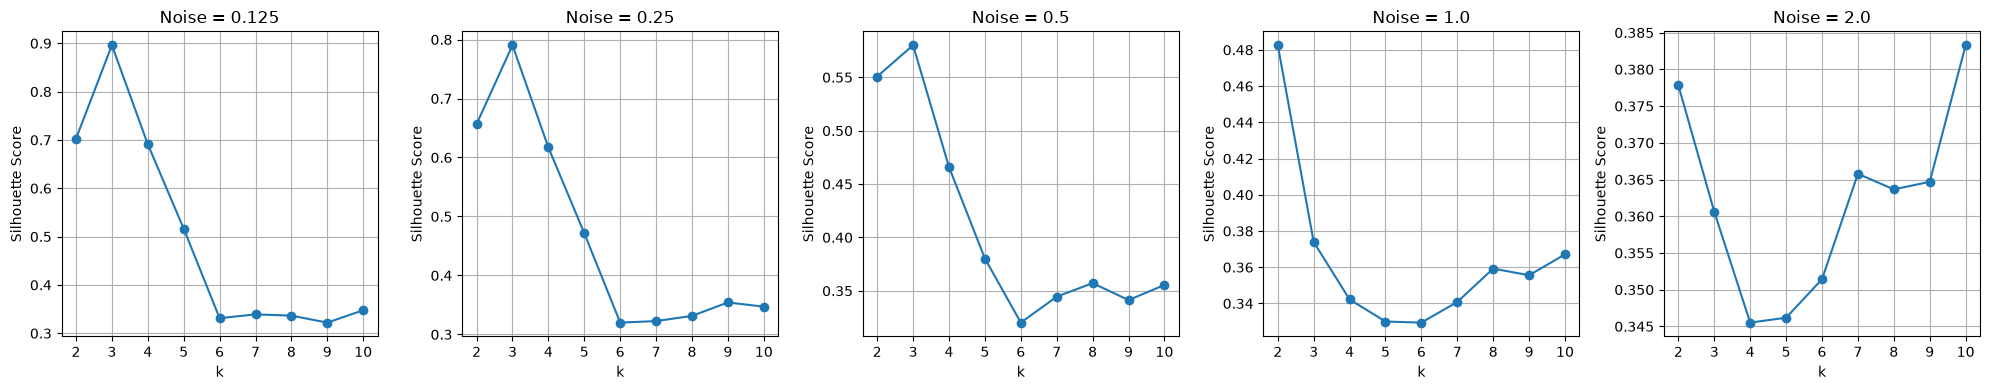

In [4]:
# Your Phase 2 solution to the problem goes here.


# Q1
# QUESTION 1:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

def createData(noise, N=50):
    np.random.seed(100)

    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])

    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})

    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

datasets = [df0_125, df0_25, df0_5, df1_0, df2_0]
noise_levels = [0.125, 0.25, 0.5, 1.0, 2.0]


# QUESTION 2:

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    sns.scatterplot(data=datasets[i], x='x1', y='x2',
                    hue='group', ax=axes[i])
    axes[i].set_title('Noise = ' + str(noise_levels[i]))
    axes[i].set_xlim(-2, 9)
    axes[i].set_ylim(-4, 9)

plt.tight_layout()
plt.show()

# Explanation:
# The clusters become more spread out when noise increases
# and start to overlap. At lower noise levels the three groups
# are much easier to tell apart. At higher noise levels, like
# 2.0, it becomes difficult to see where one group ends and
# another begins.


# IMPROVEMENT 3: Compare original groups to K-means predictions

fig, axes = plt.subplots(2, 5, figsize=(20, 8))

ari_scores = []

for i in range(5):
    X = datasets[i][['x1', 'x2']]

    model = KMeans(n_clusters=3, random_state=100, n_init=10)
    predicted = model.fit_predict(X)

    sns.scatterplot(data=datasets[i], x='x1', y='x2',
                    hue='group', ax=axes[0, i])
    axes[0, i].set_title('Original: Noise = ' + str(noise_levels[i]))

    sns.scatterplot(x=datasets[i]['x1'], y=datasets[i]['x2'],
                    hue=predicted, palette='tab10', ax=axes[1, i])
    axes[1, i].set_title('K-means: Noise = ' + str(noise_levels[i]))

    axes[0, i].set_xlim(-2, 9)
    axes[0, i].set_ylim(-4, 9)
    axes[1, i].set_xlim(-2, 9)
    axes[1, i].set_ylim(-4, 9)

    # IMPROVEMENT 5: Calculate ARI
    ari = adjusted_rand_score(datasets[i]['group'], predicted)
    ari_scores.append(ari)

plt.tight_layout()
plt.show()

# IMPROVEMENT 5: ARI scores by noise level

ari_table = pd.DataFrame({
    'Noise': noise_levels,
    'ARI Score': ari_scores
})

print(ari_table)

plt.figure(figsize=(7, 4))
plt.plot(noise_levels, ari_scores, marker='o')
plt.xlabel('Noise Level')
plt.ylabel('Adjusted Rand Index')
plt.title('Clustering Accuracy as Noise Increases')
plt.grid(True)
plt.show()

# Explanation:
# The first row shows the original groups and the second
# row shows the groups K-means predicts. At low noise,
# K-means should closely match the original groups.
# As noise increases, the predictions become less accurate.
# The ARI score measures this difference, with 1 meaning
# the predicted clusters perfectly match the original groups.



# QUESTION 3: 

# Original combined scree plot

plt.figure(figsize=(9, 6))

for i in range(5):
    X = datasets[i][['x1', 'x2']]
    inertia_values = []

    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=100, n_init=10)
        model.fit(X)
        inertia_values.append(model.inertia_)

    plt.plot(range(1, 11), inertia_values, marker='o',
             label='Noise = ' + str(noise_levels[i]))

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.title('Scree Plots for Different Noise Levels')
plt.xticks(range(1, 11))
plt.legend()
plt.grid(True)
plt.show()


# IMPROVEMENT 1: Separate scree plots for each noise level

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    X = datasets[i][['x1', 'x2']]
    inertia_values = []

    for k in range(1, 11):
        model = KMeans(n_clusters=k, random_state=100, n_init=10)
        model.fit(X)
        inertia_values.append(model.inertia_)

    axes[i].plot(range(1, 11), inertia_values, marker='o')
    axes[i].set_title('Noise = ' + str(noise_levels[i]))
    axes[i].set_xlabel('k')
    axes[i].set_ylabel('Inertia')
    axes[i].set_xticks(range(1, 11))
    axes[i].grid(True)

plt.tight_layout()
plt.show()


# IMPROVEMENT 4: Silhouette scores for different k values

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for i in range(5):
    X = datasets[i][['x1', 'x2']]
    scores = []

    for k in range(2, 11):
        model = KMeans(n_clusters=k, random_state=100, n_init=10)
        predicted = model.fit_predict(X)
        score = silhouette_score(X, predicted)
        scores.append(score)

    axes[i].plot(range(2, 11), scores, marker='o')
    axes[i].set_title('Noise = ' + str(noise_levels[i]))
    axes[i].set_xlabel('k')
    axes[i].set_ylabel('Silhouette Score')
    axes[i].set_xticks(range(2, 11))
    axes[i].grid(True)

plt.tight_layout()
plt.show()


# Explanation:
# At lower noise levels there is a clear elbow at k = 3.
# As noise increases, the elbow becomes less clear, making
# it harder to choose the best k value. Higher noise also
# increases inertia because the points are more spread out.
# At noise = 2.0, there is no obvious elbow at k = 3.
#
# The separate scree plots make the elbows easier to see
# because each graph has its own scale. The silhouette
# scores give another way to compare different k values.
# A higher silhouette score means the clusters are more
# clearly separated, which can help when the elbow is unclear.


# QUESTION 4: 

# The elbow is where adding more clusters stops making a
# big difference in reducing inertia. With three original
# groups, going from 1 to 3 clusters greatly reduces inertia
# when noise is low. After k = 3, adding more clusters only
# makes smaller improvements because the main groups are
# already separated. This is why k = 3 is a good choice
# when the noise is low.


Number of countries: 148
Spending (2020 USD)               float64
Spending per Capita               float64
Percent of Government Spending    float64
Percent of GDP                    float64
dtype: object
       Spending (2020 USD)  Spending per Capita  \
count           148.000000           148.000000   
mean          13153.747670           268.264494   
std           68005.236120           430.434878   
min               8.622460             0.580129   
25%             204.877177            20.553464   
50%             959.535443            81.506703   
75%            5289.998320           326.267753   
max          778397.200000          2520.398541   

       Percent of Government Spending  Percent of GDP  
count                      148.000000      148.000000  
mean                         0.061510        0.019619  
std                          0.046207        0.015033  
min                          0.004896        0.000054  
25%                          0.031352        0.010413

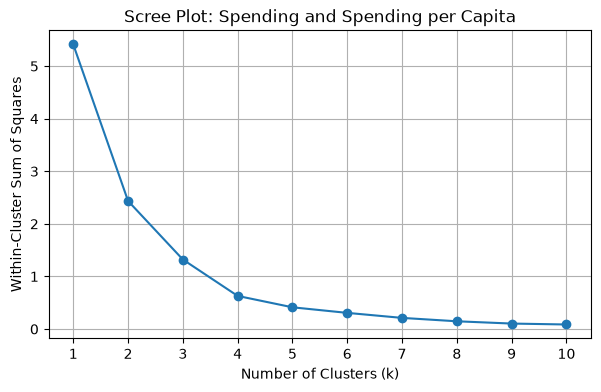

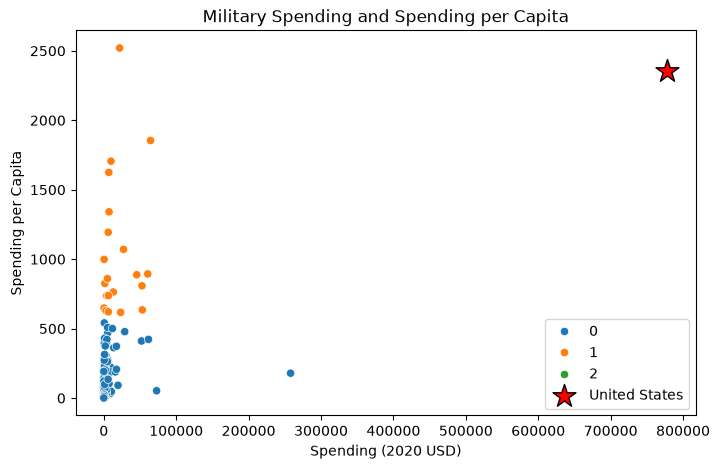

         Spending (2020 USD)                                              \
                       count           mean           std            min   
cluster2                                                                   
0                      126.0    5943.346303  24858.961064       8.622460   
1                       21.0   19975.991473  21749.736747     405.790494   
2                        1.0  778397.200000           NaN  778397.200000   

                                                                      \
                    25%            50%            75%            max   
cluster2                                                               
0            162.761743     580.758315    3225.333414  257973.429834   
1           4980.428135    7269.880030   27300.894701   64558.400000   
2         778397.200000  778397.200000  778397.200000  778397.200000   

         Spending per Capita                                        \
                       count         mea

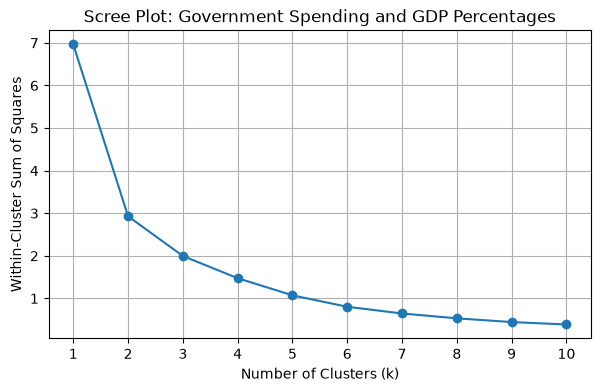

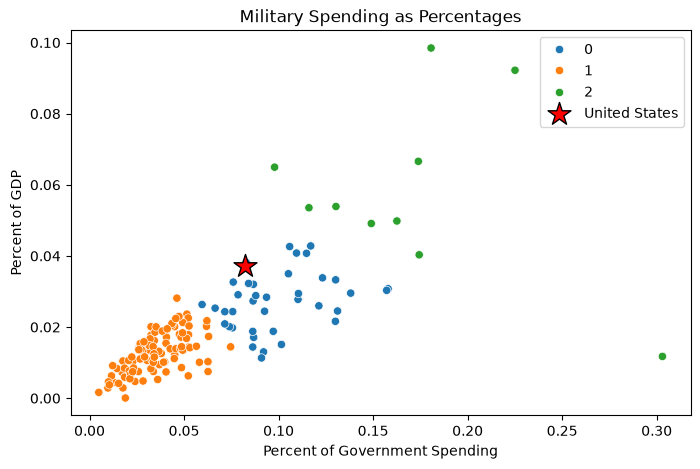

         Percent of Government Spending                                \
                                  count      mean       std       min   
cluster3                                                                
0                                  39.0  0.098683  0.024125  0.059520   
1                                  99.0  0.035777  0.014549  0.004896   
2                                  10.0  0.171289  0.058725  0.097882   

                                                 Percent of GDP            \
               25%       50%       75%       max          count      mean   
cluster3                                                                    
0         0.082430  0.092044  0.112633  0.157918           39.0  0.027412   
1         0.025921  0.034261  0.047402  0.074624           99.0  0.012664   
2         0.135010  0.168248  0.179081  0.303027           10.0  0.058071   

                                                                      
               std       mi

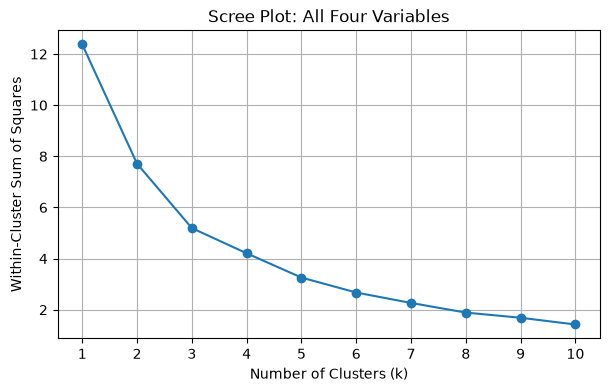

         Spending (2020 USD)                                             \
                       count           mean            std          min   
cluster4                                                                  
0                      111.0    7086.472777   26479.379918     8.622460   
1                        6.0  147964.582042  309635.189564  6095.708713   
2                       31.0    8786.086602   17901.909108   162.373364   

                                                                  \
                  25%           50%           75%            max   
cluster4                                                           
0          130.010211    567.650747   3910.107493  257973.429834   
1         7700.424616  15897.570598  53872.942442  778397.200000   
2          467.787851   1404.787234   7739.166193   72937.064048   

         Spending per Capita               ... Percent of Government Spending  \
                       count         mean  ...             

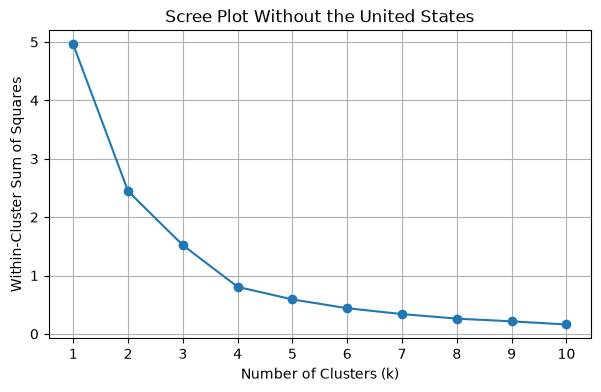

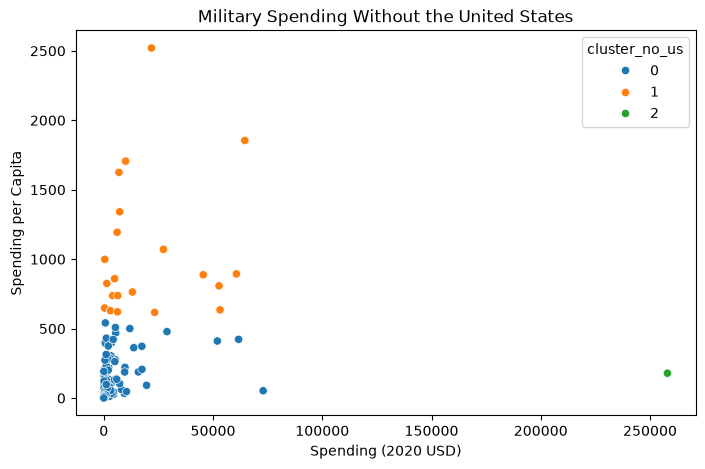

Original cluster sizes:
cluster2
0    126
1     21
2      1
dtype: int64
Cluster sizes without the US:
cluster_no_us
0    125
1     21
2      1
dtype: int64


In [6]:

# Q2
# QUESTION 1: 

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')

df = df[df['Year'] == 2020].copy()
df = df.dropna()

columns = ['Spending (2020 USD)', 'Spending per Capita',
           'Percent of Government Spending', 'Percent of GDP']

print("Number of countries:", len(df))
print(df[columns].dtypes)
print(df[columns].describe())

# Explanation:
# Filtering to 2020 and removing missing values leaves
# 148 countries. All four variables are already numeric,
# so no further cleaning is needed.


# QUESTION 2: 

cols2 = ['Spending (2020 USD)', 'Spending per Capita']

# Min-max normalization
X2 = df[cols2].copy()

for col in cols2:
    X2[col] = (X2[col] - X2[col].min()) / (X2[col].max() - X2[col].min())

# Scree plot
wcss2 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X2)
    wcss2.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss2, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Scree Plot: Spending and Spending per Capita')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# K-means clustering
model2 = KMeans(n_clusters=3, random_state=100, n_init=10)
df['cluster2'] = model2.fit_predict(X2)

# Scatterplot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=cols2[0], y=cols2[1],
                hue='cluster2', palette='tab10')

# IMPROVEMENT 2: Highlight the United States
us = df[df['Country'] == 'United States of America']

plt.scatter(us[cols2[0]], us[cols2[1]],
            color='red', marker='*', s=300,
            edgecolor='black', label='United States')

plt.title('Military Spending and Spending per Capita')
plt.legend()
plt.show()

# Describe table
print(df.groupby('cluster2')[cols2].describe())

# IMPROVEMENT 3: Simple cluster summary table
summary2 = df.groupby('cluster2')[cols2].mean()
summary2['Number of Countries'] = df.groupby('cluster2').size()

print("Cluster Summary: Spending")
print(summary2.round(2))

# United States and countries by cluster
print(df[df['Country'] == 'United States of America']
      [['Country', 'cluster2'] + cols2])

print(df.groupby('cluster2')['Country'].apply(list))

# Explanation:
# The elbow is around k = 3, so I chose three clusters.
# Most countries are in cluster 0 with lower spending
# per capita. Cluster 1 has 21 countries with higher
# spending per capita. The United States is alone in
# cluster 2 because its total spending is much higher.
# The summary table makes these differences easier to see.


# QUESTION 3: Percent of government spending and GDP

cols3 = ['Percent of Government Spending', 'Percent of GDP']

# Min-max normalization
X3 = df[cols3].copy()

for col in cols3:
    X3[col] = (X3[col] - X3[col].min()) / (X3[col].max() - X3[col].min())

# Scree plot
wcss3 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X3)
    wcss3.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss3, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Scree Plot: Government Spending and GDP Percentages')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# K-means clustering
model3 = KMeans(n_clusters=3, random_state=100, n_init=10)
df['cluster3'] = model3.fit_predict(X3)

# Scatterplot
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x=cols3[0], y=cols3[1],
                hue='cluster3', palette='tab10')

# IMPROVEMENT 2: Highlight the United States
plt.scatter(us[cols3[0]], us[cols3[1]],
            color='red', marker='*', s=300,
            edgecolor='black', label='United States')

plt.title('Military Spending as Percentages')
plt.legend()
plt.show()

# Describe table
print(df.groupby('cluster3')[cols3].describe())

# IMPROVEMENT 3: Simple cluster summary table
summary3 = df.groupby('cluster3')[cols3].mean()
summary3['Number of Countries'] = df.groupby('cluster3').size()

print("Cluster Summary: Spending Percentages")
print(summary3.round(4))

# United States and countries by cluster
print(df[df['Country'] == 'United States of America']
      [['Country', 'cluster3'] + cols3])

print(df.groupby('cluster3')['Country'].apply(list))

# Explanation:
# The scree plot suggests around three clusters, but
# the elbow is less clear. Cluster 1 has the lowest
# spending percentages, cluster 0 is in the middle,
# and cluster 2 has the highest.
# The United States is now in cluster 0 instead of
# being alone because we are comparing percentages
# rather than total spending.


# QUESTION 4: 

X4 = df[columns].copy()

# Min-max normalization
for col in columns:
    X4[col] = (X4[col] - X4[col].min()) / (X4[col].max() - X4[col].min())

# Scree plot
wcss4 = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X4)
    wcss4.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss4, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Scree Plot: All Four Variables')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# K-means clustering
model4 = KMeans(n_clusters=3, random_state=100, n_init=10)
df['cluster4'] = model4.fit_predict(X4)

# Describe table
print(df.groupby('cluster4')[columns].describe())

# IMPROVEMENT 3: Simple cluster summary table
summary4 = df.groupby('cluster4')[columns].mean()
summary4['Number of Countries'] = df.groupby('cluster4').size()

print("Cluster Summary: All Four Variables")
print(summary4.round(4))

# Compare clusters
print(pd.crosstab(df['cluster2'], df['cluster4']))
print(pd.crosstab(df['cluster3'], df['cluster4']))

# United States and countries by cluster
print(df[df['Country'] == 'United States of America']
      [['Country', 'cluster2', 'cluster3', 'cluster4']])

print(df.groupby('cluster4')['Country'].apply(list))

# IMPROVEMENT 4: Compare country assignments across models
comparison = df[['Country', 'cluster2', 'cluster3', 'cluster4']].copy()

print("Country Cluster Comparison")
print(comparison.sort_values('Country').to_string(index=False))

# Show which countries are grouped with the US in each model
us = df[df['Country'] == 'United States of America']

us_cluster2 = us['cluster2'].iloc[0]
us_cluster3 = us['cluster3'].iloc[0]
us_cluster4 = us['cluster4'].iloc[0]

print("Countries in the same cluster as the US in Question 2:")
print(df[df['cluster2'] == us_cluster2]['Country'].tolist())

print("Countries in the same cluster as the US in Question 3:")
print(df[df['cluster3'] == us_cluster3]['Country'].tolist())

print("Countries in the same cluster as the US in Question 4:")
print(df[df['cluster4'] == us_cluster4]['Country'].tolist())

# Explanation:
# Using all four variables, I chose k = 3 to compare
# with the previous questions. Cluster 0 contains most
# countries with lower spending percentages and spending
# per capita. Cluster 1 has six countries with high
# spending per capita, and cluster 2 contains countries
# spending a larger percentage on their military.
#
# Unlike Question 2, the US is no longer alone because
# the model now considers all four variables.
# The comparison table shows how countries can be
# grouped differently depending on the variables used.


# QUESTION 5: Usefulness of K-means clustering

# IMPROVEMENT 5: Repeat Question 2 without the United States

df_no_us = df[df['Country'] != 'United States of America'].copy()

X_no_us = df_no_us[cols2].copy()

# Normalize again without the US
for col in cols2:
    X_no_us[col] = (X_no_us[col] - X_no_us[col].min()) / (X_no_us[col].max() - X_no_us[col].min())

# Scree plot without the US
wcss_no_us = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=100, n_init=10)
    model.fit(X_no_us)
    wcss_no_us.append(model.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(1, 11), wcss_no_us, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Within-Cluster Sum of Squares')
plt.title('Scree Plot Without the United States')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# Cluster without the US
model_no_us = KMeans(n_clusters=3, random_state=100, n_init=10)
df_no_us['cluster_no_us'] = model_no_us.fit_predict(X_no_us)

# Scatterplot without the US
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_no_us, x=cols2[0], y=cols2[1],
                hue='cluster_no_us', palette='tab10')
plt.title('Military Spending Without the United States')
plt.show()

# Compare cluster sizes
print("Original cluster sizes:")
print(df.groupby('cluster2').size())

print("Cluster sizes without the US:")
print(df_no_us.groupby('cluster_no_us').size())

# Explanation:
# K-means was useful because it showed differences in
# how countries spend on their military. Some spend
# more overall, while others spend a larger percentage
# of their resources.
#
# Removing the United States lets us see how much one
# extreme value can affect the clustering results.
# The clusters may change because the US is no longer
# included in the data or the normalization.
# This shows why outliers are important to consider
# when using K-means.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The improvements AI made on this assignment definitely outweighed the mistakes, but both were still present.  Some of the main improvements AI made on question 1 were that it suggested different changes and techniques that helped me identify the elbow at different noise levels better. For question 2, a big improvement was that the AI assisted with adding summary tables and playing around with the US to see the impact the US alone had on the dataset. One of the main limitations AI had with working with this assignment is that it provided me with a coding error that I had to correct. It suggested I created the US data frame before all the cluster columns were added, and this resulted in an error when trying to access those columns later. I had to identify what was causing the problem and asked AI to tell me how to fix it, as it was something that AI originally suggested, so I was not too familiar with it. How I went about verifying AI improvements was running the notebook and comparing it to my original code and claims. I had to verify that they did not contradict one another, and if they did, I would do research on which answer was correct.
